## Setup

In [2]:
import pandas as pd  # tables of data
import matplotlib.pyplot as plt  # charts
import matplotlib.patheffects as pe  # text outlines

data_path = "/content/drive/My Drive/neet_data.csv"  # where the cleaned data lives on Drive
fig5_path = "/content/drive/My Drive/fig5_neet_total_by_sex_2013_2026.png"  # where the line chart is saved on Drive

## Mount Google Drive

In [3]:
from google.colab import drive  # Colab's Google Drive tool
drive.mount("/content/drive")  # connect Google Drive

Mounted at /content/drive


## Load the data

In [4]:
df = pd.read_csv(data_path)  # load the cleaned data into a table

## Table 6: NEET rate by year and sex, ages 16 to 24, 2013 to 2026

In [5]:
def wmean(data, var):  # weighted mean of one variable
    d = data.dropna(subset=[var])  # leave out people with a missing value
    return (d[var] * d["asecwt"]).sum() / d["asecwt"].sum()  # sum of value x weight, divided by sum of weights

years = list(range(2013, 2027))  # the years in the table, 2013 to 2026
sample = df[df["year"].isin(years) & ((df["age16_19"] == 1) | (df["age20_24"] == 1))].copy()  # keep 2013 to 2026 and ages 16 to 24

male_name = df.loc[df["female"] == 0, "sex_label"].iloc[0]  # the sex_label for female = 0
female_name = df.loc[df["female"] == 1, "sex_label"].iloc[0]  # the sex_label for female = 1

left_out = sample["neet"].isna().groupby(sample["year"]).sum()  # people left out in each year because neet is missing
known = sample.dropna(subset=["neet"])  # keep only people whose neet is known

# empty tables, filled in below: one row per year, columns Total, Male, Female
columns = ["Total", male_name, female_name]  # the three columns
table = pd.DataFrame(0.0, index=years, columns=columns)  # weighted NEET rate
people = pd.DataFrame(0, index=years, columns=columns)  # unweighted respondents

for year in years:  # loop over the years
    everyone = known[known["year"] == year]  # all people in this year
    men = everyone[everyone["female"] == 0]  # men in this year
    women = everyone[everyone["female"] == 1]  # women in this year
    for column, group in [("Total", everyone), (male_name, men), (female_name, women)]:  # the three columns
        table.loc[year, column] = wmean(group, "neet") * 100  # weighted percent NEET
        people.loc[year, column] = len(group)  # unweighted respondents in this cell

print("People left out because neet is missing, by year (unweighted):")  # left-out title
print(left_out.to_string())  # one number per year
print()  # empty line
print("Table 6. NEET rate, % of people aged 16 to 24 with a known neet (weighted with asecwt).")  # table title
print(table.to_string(float_format="{:.1f}".format))  # table, 1 decimal
print()  # empty line
print("Check: every year from 2013 to 2026 is in the table:", list(table.index) == years)  # True or False
print("Check: every year has a value in all three columns:", bool(table.notna().all().all()))  # True or False
print()  # empty line
print("Unweighted number of respondents in each cell (neet not missing).")  # counts title
print(people.to_string())  # counts, same layout

People left out because neet is missing, by year (unweighted):
year
2013    111
2014    130
2015    135
2016    111
2017     90
2018    100
2019    107
2020     92
2021     94
2022     92
2023     83
2024     70
2025     75
2026     61

Table 6. NEET rate, % of people aged 16 to 24 with a known neet (weighted with asecwt).
      Total  Male  Female
2013   14.4  13.9    14.8
2014   13.9  13.3    14.4
2015   13.7  12.8    14.7
2016   13.1  12.7    13.6
2017   11.2  10.7    11.7
2018   11.4  10.9    11.8
2019   10.9  10.5    11.4
2020   12.5  12.7    12.3
2021   13.5  13.8    13.3
2022   12.7  12.2    13.3
2023   11.1  10.5    11.7
2024   12.1  11.6    12.5
2025   11.8  11.9    11.7
2026   11.5  11.2    11.8

Check: every year from 2013 to 2026 is in the table: True
Check: every year has a value in all three columns: True

Unweighted number of respondents in each cell (neet not missing).
      Total   Male  Female
2013  24160  12092   12068
2014  23429  11811   11618
2015  23225  11746   

**What one cell means.** Take the row 2019 and the column "Female". Among women aged 16 to 24 in the 2019 survey whose NEET status is known, the cell is the percent who were NEET: not employed and not in school. The column "Male" is the same percent for men, and the column "Total" is the same percent for men and women together. People whose NEET status could not be determined are left out, not counted as zero. People are counted by how many people in the country they represent (`asecwt`), so each number describes the population, not just the people surveyed. A cell of 10.0 means 10 out of every 100 such people were NEET. The count table under the table shows how many survey respondents sit behind each cell.

## Figure 5: NEET rate by year and sex, ages 16 to 24, 2013 to 2026

Table 6. NEET rate, % of people aged 16 to 24 with a known neet (weighted with asecwt). Figure 5 shows this table.
      Total  Male  Female
2013   14.4  13.9    14.8
2014   13.9  13.3    14.4
2015   13.7  12.8    14.7
2016   13.1  12.7    13.6
2017   11.2  10.7    11.7
2018   11.4  10.9    11.8
2019   10.9  10.5    11.4
2020   12.5  12.7    12.3
2021   13.5  13.8    13.3
2022   12.7  12.2    13.3
2023   11.1  10.5    11.7
2024   12.1  11.6    12.5
2025   11.8  11.9    11.7
2026   11.5  11.2    11.8


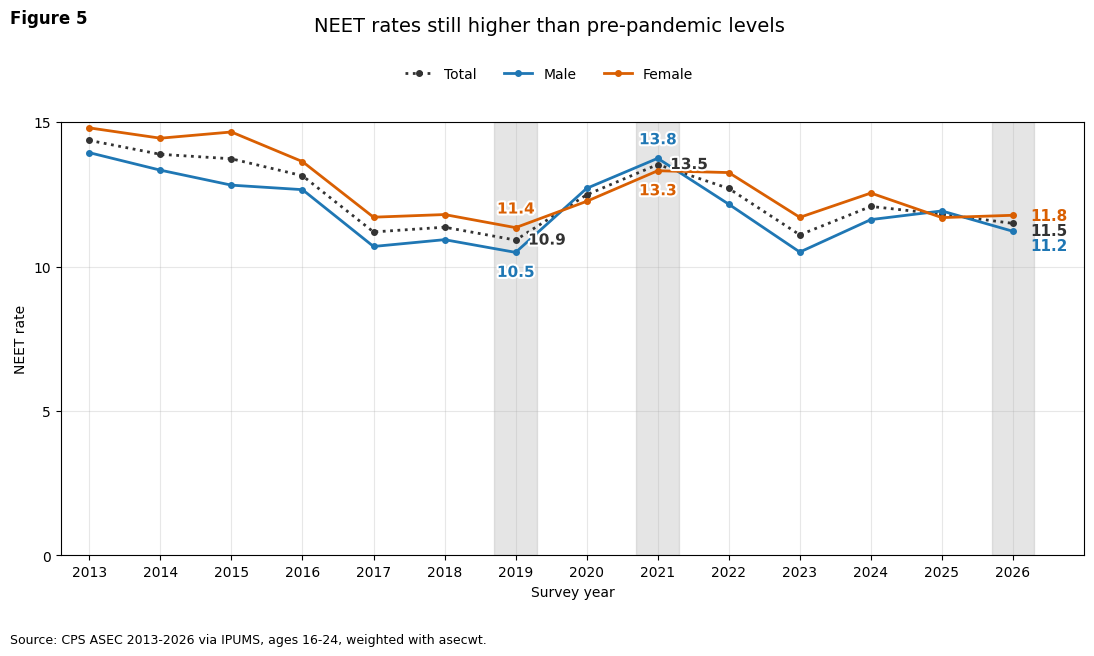

In [6]:
chart_title = "NEET rates still higher than pre-pandemic levels"  # chart title

print("Table 6. NEET rate, % of people aged 16 to 24 with a known neet (weighted with asecwt). Figure 5 shows this table.")  # table title
print(table.to_string(float_format="{:.1f}".format))  # table, 1 decimal

# settings
line_styles = {"Total": ":", male_name: "-", female_name: "-"}  # Total dotted, Male and Female solid
line_colors = {"Total": "#333333", male_name: "#1f77b4", female_name: "#d95f02"}  # a different color for each line
ymax = int(table.max().max() / 5) * 5 + 5  # round number just above the highest value in the table
last_year = table.index.max()  # the last year, 2026
outline = [pe.withStroke(linewidth=3, foreground="white")]  # thin white outline around the numbers

# grey columns behind the lines, then one line for each column
fig, ax = plt.subplots(figsize=(11, 6.5))  # one chart
for year in [2019, 2021, last_year]:  # the three highlighted years
    ax.axvspan(year - 0.3, year + 0.3, color="gray", alpha=0.2, zorder=0)  # translucent grey column behind the lines
for column in table.columns:  # one line for each column: Total, Male, Female
    ax.plot(table.index, table[column],  # years and values
        linestyle=line_styles[column], color=line_colors[column],  # dotted or solid, in its own color
        marker="o", markersize=4, linewidth=2, label=column)  # small marker on each point

# the value of the last year at the end of each line
min_gap = ymax * 0.035  # smallest vertical space between two end labels
label_y_above = float("inf")  # height of the label above, the first label has nothing above it
for column, value in table.loc[last_year].sort_values(ascending=False).items():  # from the highest line to the lowest
    label_y = min(value, label_y_above - min_gap)  # move a label down if it would overlap the one above
    ax.text(last_year + 0.25, label_y, f"{value:.1f}",  # just right of the last year, with the value as text
            color=line_colors[column], va="center", ha="left", fontsize=11, fontweight="bold")  # in the color of the line
    label_y_above = label_y  # the next label must sit below this one

# the values of 2019 and 2021 next to their points
def write_value(year, column, x_shift, y_shift, horizontal, vertical):  # writes one value next to its point
    value = table.loc[year, column]  # the value to write
    ax.annotate(f"{value:.1f}", (year, value),  # the number, and the point it belongs to
                xytext=(x_shift, y_shift), textcoords="offset points",  # where to write it, relative to the point
                ha=horizontal, va=vertical,  # how the text lines up with that spot
                color=line_colors[column], fontsize=11, fontweight="bold",  # in the color of the line
                path_effects=outline)  # with a white outline

for year in [2019, 2021]:  # years to label in the middle of the chart
    if table.loc[year, male_name] >= table.loc[year, female_name]:  # Male is the higher line
        higher, lower = male_name, female_name  # Male above, Female below
    else:  # Female is the higher line
        higher, lower = female_name, male_name  # Female above, Male below
    write_value(year, higher, 0, 8, "center", "bottom")  # higher line: value above the point
    write_value(year, lower, 0, -9, "center", "top")  # lower line: value below the point
    write_value(year, "Total", 9, 0, "left", "center")  # Total line: value to the right of the point

# axes
ax.set_xticks(list(table.index))  # a tick for every year
ax.set_xlim(table.index.min() - 0.4, last_year + 1.0)  # room at the right for the end labels
ax.set_xlabel("Survey year")  # x-axis label
ax.set_ylabel("NEET rate")  # y-axis label
ax.set_ylim(0, ymax)  # y-axis starts at 0
ax.set_yticks(range(0, ymax + 1, 5))  # y ticks every 5, starting at 0
ax.grid(True, alpha=0.3)  # light grid

# legend, title and note
handles, labels = ax.get_legend_handles_labels()  # the three lines
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.92), ncol=3, frameon=False)  # one legend
fig.suptitle(chart_title, fontsize=14, y=0.98)  # chart title
fig.text(0.01, 0.99, "Figure 5", fontsize=12, fontweight="bold", va="top")  # figure label, top left
fig.tight_layout(rect=[0, 0.06, 1, 0.9])  # leave room for the title, legend and note
fig.text(0.01, 0.015, "Source: CPS ASEC 2013-2026 via IPUMS, ages 16-24, weighted with asecwt.", fontsize=9)  # source note

# save and show
fig.savefig(fig5_path, dpi=200, bbox_inches="tight")  # save to Drive before showing
plt.show()  # show the chart

## Write-up (50-100 words)

Question:

Finding: